# Análisis de sentimientos

https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english

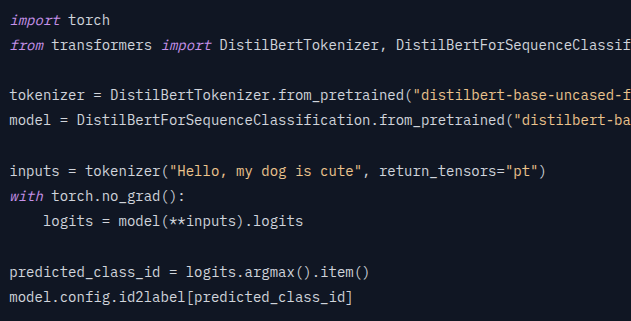

Se utiliza el ejemplo provisto en:

 https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english#model-details

In [5]:
import torch
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")

inputs = tokenizer("Hello, my dog is cute", return_tensors="pt")
with torch.no_grad():
    logits = model(**inputs).logits

predicted_class_id = logits.argmax().item()
model.config.id2label[predicted_class_id]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

'POSITIVE'

## BERT

BERT (Bidirectional Encoder Representations from Transformers) es un modelo de inteligencia artificial desarrollado por Google en 2018 que revolucionó la forma en que las computadoras entienden el lenguaje.



### Características

* **Lectura Bidireccional Real**. BERT analiza el contexto completo de una palabra mirando simultáneamente las palabras que están antes y después de ella. Por ejemplo, entiende la diferencia entre "fui al banco a depositar dinero" y "me senté en el banco del parque" gracias a las palabras que rodean a "banco".
* **Arquitectura Transformer (Encoder)**. Utiliza únicamente la parte **"codificadora"** de la arquitectura Transformer (la misma base tecnológica que luego dio origen a los modelos GPT). Su especialidad es comprender y representar el significado del texto, no escribir historias.

* **Entrenamiento en dos fases**:
	* **Pre-entrenamiento**: Se entrenó con cantidades masivas de texto sin etiquetar (como toda Wikipedia en inglés y miles de libros) usando dos trucos: adivinar palabras ocultas en una frase (Masked Language Modeling) y predecir si una frase sigue lógicamente a otra (Next Sentence Prediction).
	* **Ajuste fino (Fine-tuning)**: Una vez que ya "sabe" el idioma, se puede adaptar fácilmente a tareas específicas con pocos datos adicionales.

### Importancia
* **Cambió los buscadores web**. Google integró BERT en su motor de búsqueda en 2019 para entender mejor las consultas largas y conversacionales de los usuarios, fijándose en preposiciones pequeñas (como "para" o "sin") que antes ignoraba.
* **Nació una familia de modelos modernos**:
  * **RoBERTa** (entrenado con más datos)
  * **ALBERT** (más ligero)
  * **BETO** (entrenado específicamente en español)
  * **DistilBERT** (versión rápida y compacta)


## Distilbert

DistilBERT es una versión más pequeña, rápida y ligera del modelo de procesamiento de lenguaje natural (NLP) BERT, creada por la empresa Hugging Face en 2019.


* Se entrena como un modelo "estudiante" que aprende a imitar el comportamiento de un modelo "maestro" mucho más grande (BERT-base).
* 40% más pequeño. Tiene aproximadamente 66 millones de parámetros (frente a los 110 millones de BERT-base), lo que reduce drásticamente el espacio que ocupa en memoria.
* 60% más rápido. Al eliminar la mitad de las capas del transformador (tiene 6 capas en lugar de 12), procesa los textos a gran velocidad, incluso sin tarjetas gráficas (GPU) potentes.
* Retiene el 97% del rendimiento. A pesar de ser mucho más ligero, mantiene casi toda la precisión y capacidad de comprensión de lenguaje del modelo original.
* Arquitectura tipo Encoder (Codificador). Lee el texto de forma bidireccional (de izquierda a derecha y de derecha a izquierda al mismo tiempo), esto le permite entender el contexto.


### Usos comunes de Distilbert

* **Análisis de sentimientos**: Clasificar reseñas o comentarios como positivos, negativos o neutrales.
* **Clasificación de texto y detección de intenciones**: Organizar correos electrónicos, detectar spam o dirigir consultas en chatbots.
* **Extracción de entidades (NER)**: Identificar nombres de personas, empresas, fechas o lugares dentro de un documento.
* **Búsqueda semántica**: Encontrar respuestas exactas dentro de un texto dado (Question Answering extractivo).






In [6]:
from transformers import pipeline


## Usando pipelines


In [7]:

classification_pipeline = pipeline(task="sentiment-analysis", # or text-classification
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
  )
result = classification_pipeline("I really liked the movie!!")

print(result)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9998093247413635}]


# Análsisis de sentimientos en español

In [8]:
# Cargar el modelo preentrenado
analizador = pipeline(
    "sentiment-analysis",
    model="pysentimiento/robertuito-sentiment-analysis"
)

# Probar con frases en español
textos = [
    "¡Qué gran servicio, me encantó la atención!",
    "El paquete llegó tarde y la caja estaba rota.",
    "La reunión empieza a las 4 de la tarde."
]

resultados = analizador(textos)
for texto, res in zip(textos, resultados):
    print(f"Texto: {texto}\nSentimiento: {res['label']} (Confianza: {res['score']:.2f})\n")


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Texto: ¡Qué gran servicio, me encantó la atención!
Sentimiento: POS (Confianza: 0.98)

Texto: El paquete llegó tarde y la caja estaba rota.
Sentimiento: NEG (Confianza: 0.82)

Texto: La reunión empieza a las 4 de la tarde.
Sentimiento: NEU (Confianza: 0.87)



In [9]:

# Modelo ideal para redacción formal y noticias
analizador = pipeline(
    "sentiment-analysis",
    model="UMUTeam/roberta-spanish-sentiment-analysis",
    truncation=True,
    max_length=512
)

noticias = [
    "La inflación anual mostró una desaceleración inesperada durante el último trimestre, impulsando la confianza de los inversionistas.",
    "El cierre de la autopista principal provocó pérdidas millonarias y retrasos en el transporte de mercancías.",
    "El congreso sesionará el próximo martes para discutir el presupuesto anual de infraestructura."
]

resultados = analizador(noticias)
for noticia, res in zip(noticias, resultados):
    print(f"Noticia: {noticia}\nTono: {res['label']} (Confianza: {res['score']:.2f})\n")


config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/851k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/509k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.66M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

Noticia: La inflación anual mostró una desaceleración inesperada durante el último trimestre, impulsando la confianza de los inversionistas.
Tono: neutral (Confianza: 0.99)

Noticia: El cierre de la autopista principal provocó pérdidas millonarias y retrasos en el transporte de mercancías.
Tono: negative (Confianza: 1.00)

Noticia: El congreso sesionará el próximo martes para discutir el presupuesto anual de infraestructura.
Tono: neutral (Confianza: 1.00)



## Clasificación de noticias fake y reales

El modelo **Juanillaberia/spanish-fake-news-classifier** es un clasificador binario basado en BETO (dccuchile/bert-base-spanish-wwm-uncased) diseñado para detectar si un artículo periodístico en español es real (1) o falso (0).
Dado que este modelo fue ajustado específicamente para artículos largos (long-form journalism) con un límite de 512 tokens, funciona mejor cuando le pasas párrafos completos con estructura periodística en lugar de titulares sueltos.


Tiene una precisión general (Accuracy) del 82.05% en su conjunto de prueba. Detecta patrones lingüísticos asociados a la desinformación (lenguaje alarmista, falta de fuentes verificables, estructuras de bulos), pero no verifica hechos en tiempo real contra internet.

In [10]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# Cargar el modelo y el tokenizador
model_name = "Juanillaberia/spanish-fake-news-classifier"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval() # Poner en modo evaluación


config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/736k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(31002, 768, padding_idx=1)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [12]:
def predict_article(article_text: str):
    inputs = tokenizer(
        article_text,
        truncation=True,
        max_length=512,
        padding="max_length",
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = torch.softmax(logits, dim=-1)
        predicted_label_id = torch.argmax(probabilities, dim=-1).item()
        confidence = probabilities[0][predicted_label_id].item()

    # Nota del autor: 1 es 'Real' y 0 es 'Fake'
    label = "Real" if predicted_label_id == 1 else "Fake"
    return label, confidence

In [13]:
## Noticias de prueba
noticias_prueba = [
    {
        "esperado": "Real",
        "texto": (
            "El Banco Central anunció este martes que mantendrá la tasa de interés de referencia "
            "sin cambios en el 4.5% anual, tras evaluar los últimos datos de inflación subyacente y el "
            "comportamiento del mercado laboral. Según el comunicado oficial emitido por la junta de gobierno, "
            "la decisión busca consolidar la convergencia de los precios hacia la meta establecida para el próximo año, "
            "manteniendo una postura prudente ante la volatilidad de los mercados internacionales."
        )
    },
    {
        "esperado": "Real",
        "texto": (
            "Investigadores de la Universidad Nacional presentaron los resultados de un estudio sobre la "
            "recuperación de arrecifes de coral mediante técnicas de microfragmentación. El proyecto, desarrollado "
            "durante tres años en la costa del Caribe, demostró que las colonias cultivadas en viveros submarinos "
            "lograron una tasa de supervivencia superior al 70% tras ser trasplantadas a zonas degradadas por el "
            "aumento de la temperatura del agua."
        )
    },
    {
        "esperado": "Fake",
        "texto": (
            "¡URGENTE! El gobierno acaba de aprobar en secreto una ley que permitirá confiscar automáticamente "
            "el 30% de todos los ahorros bancarios privados a partir del próximo lunes para financiar gastos políticos. "
            "Fuentes anónimas revelaron que los bancos ya recibieron la orden de bloquear los retiros en cajeros "
            "automáticos este fin de semana. ¡Comparte este mensaje antes de que censuren la noticia en todos los medios!"
        )
    },
    {
        "esperado": "Fake",
        "texto": (
            "Científicos independientes descubren que beber tres vasos de agua tibia con limón y bicarbonato "
            "en ayunas elimina por completo cualquier tipo de célula cancerígena en menos de 48 horas. La industria "
            "farmacéutica lleva décadas ocultando este remedio casero porque acabaría con el negocio de las "
            "quimioterapias. Médicos de todo el mundo están renunciando tras filtrarse el documento confidencial."
        )
    }
]


In [14]:
for i, item in enumerate(noticias_prueba, 1):
    prediccion, confianza = predict_article(item["texto"])
    print(f"--- Noticia {i} ---")
    print(f"Etiqueta esperada: {item['esperado']}")
    print(f"Predicción modelo: {prediccion} (Confianza: {confianza:.2%})\n")

--- Noticia 1 ---
Etiqueta esperada: Real
Predicción modelo: Real (Confianza: 98.58%)

--- Noticia 2 ---
Etiqueta esperada: Real
Predicción modelo: Real (Confianza: 97.60%)

--- Noticia 3 ---
Etiqueta esperada: Fake
Predicción modelo: Fake (Confianza: 94.78%)

--- Noticia 4 ---
Etiqueta esperada: Fake
Predicción modelo: Fake (Confianza: 98.68%)

